# LokerLens — Pelatihan Model Klasifikasi (asli vs palsu)

Input: `ml/data/processed/dataset_lokerlens_bersih.csv` (dibuat oleh `ml/scraping/rapikan_dataset.py`).
Model **hanya membaca kolom `deskripsi`**. Kolom `nama_perusahaan` dan `posisi` tidak dipakai karena persen terisinya berbeda antar kelas (bisa membocorkan label).

Output: `ml/models/model_lokerlens.joblib` + `ml/models/model_lokerlens_meta.json`.

> Output sistem = alat bantu keputusan, bukan penetapan penipuan (BR-04 di SRS).

## 1. Setup

In [1]:
import json, sys, warnings, datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_fscore_support)

warnings.filterwarnings("ignore")
SEED = 42
AMBANG_PRIORITAS = 0.70      # BR-05: disepakati tim, harus sama dengan config/lokerlens.php (70)

# folder ml/ ditemukan otomatis (jalan dari ml/notebooks, ml/, atau root repo)
ML_DIR = next(p for p in [Path.cwd(), Path.cwd().parent, Path.cwd() / "ml"] if (p / "data" / "processed").exists())
PATH_DATASET = ML_DIR / "data" / "processed" / "dataset_lokerlens_bersih.csv"
DIR_MODEL = ML_DIR / "models"; DIR_MODEL.mkdir(exist_ok=True)

sys.path.insert(0, str(ML_DIR / "src"))
from lokerlens_infer import preprocess, periksa, _bobot_fitur
print("ML_DIR:", ML_DIR)

ML_DIR: c:\Users\tanst\LokerLens\ml


## 2. Muat & siapkan data

In [2]:
df = pd.read_csv(PATH_DATASET)[["label", "deskripsi"]].dropna()
df["teks_bersih"] = df["deskripsi"].map(preprocess)
df = df[df["teks_bersih"].str.split().str.len() >= 5].drop_duplicates("teks_bersih").reset_index(drop=True)

# postingan hampir-kembar (10 token awal sama) dijadikan satu grup supaya tidak terpisah antara train dan test
df["grup"] = pd.factorize(df["teks_bersih"].map(lambda s: " ".join(s.split()[:10])))[0]
df["n_char"] = df["deskripsi"].str.len()

print(len(df), "baris |", df["label"].map({0: "asli", 1: "palsu"}).value_counts().to_dict())
print(df.groupby("label")["n_char"].agg(["mean", "median"]).round(0).rename(index={0: "asli", 1: "palsu"}))

# seberapa jauh PANJANG TEKS saja bisa menebak label? (tinggi = risiko model 'menyontek' dari panjang)
p_len = cross_val_predict(LogisticRegression(), np.log1p(df[["n_char"]]), df["label"],
                          cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), groups=df["grup"], method="predict_proba")[:, 1]
print("ROC-AUC dari panjang teks saja:", round(roc_auc_score(df["label"], p_len), 3))

824 baris | {'asli': 498, 'palsu': 326}
        mean  median
label               
asli   908.0   762.0
palsu  408.0   346.0
ROC-AUC dari panjang teks saja: 0.825


## 3. Split data (20% test, group-aware)

In [3]:
X, y, grp = df["teks_bersih"], df["label"], df["grup"]
idx_tr, idx_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, grp))
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te], grp.iloc[idx_tr]
print("Train:", len(X_tr), "| Test:", len(X_te), "| palsu di test:", int(y_te.sum()))

Train: 659 | Test: 165 | palsu di test: 65


## 4. Bandingkan 4 model (CV 5-fold pada data train)

In [4]:
def buat_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, max_features=20000, sublinear_tf=True)

kandidat = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "SVM (linear)": CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=SEED), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED),
}
cv = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
skor = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

baris = []
for nama, clf in kandidat.items():
    s = cross_validate(Pipeline([("tfidf", buat_tfidf()), ("clf", clf)]), X_tr, y_tr,
                       cv=cv, groups=g_tr, scoring=skor, n_jobs=-1)
    baris.append({"model": nama, **{k: s[f"test_{k}"].mean() for k in skor}, "f1_std": s["test_f1"].std()})

hasil_cv = pd.DataFrame(baris).set_index("model").sort_values(["f1", "recall"], ascending=False)
display(hasil_cv.round(4))

MODEL_FINAL = hasil_cv.index[0]    # ganti manual kalau selisih tipis, mis. "Logistic Regression" (kata pemicu lebih bermakna)
print("Model final:", MODEL_FINAL)

,accuracy,precision,recall,f1,roc_auc,f1_std
model,,,,,,
Logistic Regression,0.9833,0.9809,0.9769,0.9788,0.9994,0.0167
SVM (linear),0.9833,0.9846,0.9731,0.9787,0.9994,0.0143
Naive Bayes,0.9818,0.9923,0.9616,0.9765,0.9991,0.0103
Random Forest,0.9651,0.9509,0.9616,0.9561,0.9952,0.0133


Model final: Logistic Regression


## 5. Evaluasi di test set

              precision    recall  f1-score   support

        asli     0.9802    0.9900    0.9851       100
       palsu     0.9844    0.9692    0.9767        65

    accuracy                         0.9818       165
   macro avg     0.9823    0.9796    0.9809       165
weighted avg     0.9818    0.9818    0.9818       165

ROC-AUC: 0.9986


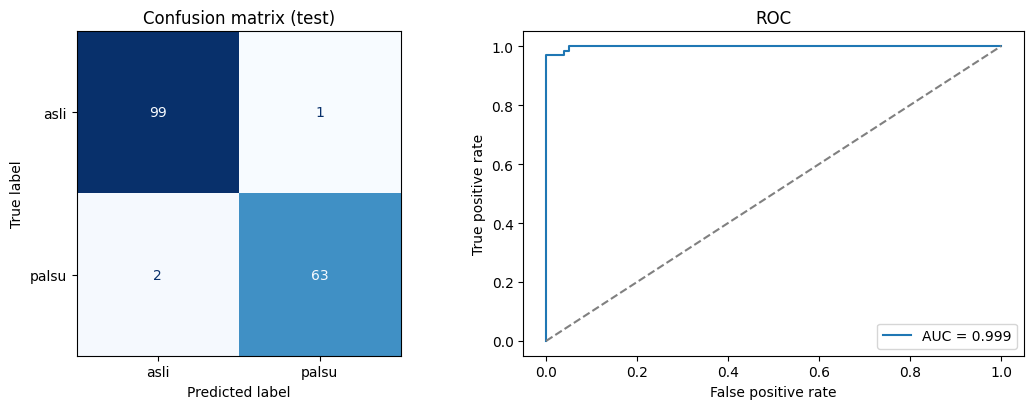

In [5]:
pipe_final = Pipeline([("tfidf", buat_tfidf()), ("clf", clone(kandidat[MODEL_FINAL]))]).fit(X_tr, y_tr)
proba = pipe_final.predict_proba(X_te)[:, 1]
pred = (proba >= 0.5).astype(int)
print(classification_report(y_te, pred, target_names=["asli", "palsu"], digits=4))
auc = roc_auc_score(y_te, proba); print("ROC-AUC:", round(auc, 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["asli", "palsu"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_te, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC"); ax[1].legend()
plt.tight_layout(); plt.show()

### 5.1 Uji ketahanan: samakan panjang teks (potong 80 token pertama)

In [6]:
def uji(teks):
    a, b = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(teks, y, grp))
    m = Pipeline([("tfidf", buat_tfidf()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))]).fit(teks.iloc[a], y.iloc[a])
    pr = m.predict_proba(teks.iloc[b])[:, 1]
    p, r, f, _ = precision_recall_fscore_support(y.iloc[b], (pr >= 0.5).astype(int), average="binary")
    return {"precision": p, "recall": r, "f1": f, "roc_auc": roc_auc_score(y.iloc[b], pr)}

pd.DataFrame({"teks penuh": uji(X), "dipotong 80 token": uji(X.map(lambda s: " ".join(s.split()[:80])))}).T.round(4)

,precision,recall,f1,roc_auc
teks penuh,0.9844,0.9692,0.9767,0.9986
dipotong 80 token,1.0000,0.9538,0.9764,0.9986


Kalau skor turun jauh saat teks dipotong, sebagian skor datang dari **panjang/gaya penulisan per sumber**. Catat di laporan sebagai keterbatasan: asli berasal dari KarirHub, palsu dari TurnBackHoax.

### 5.2 Sensitivitas ambang prioritas tinggi (BR-05)

In [7]:
rows = []
for th in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    f = proba >= th
    tp = int((f & (y_te.values == 1)).sum())
    rows.append({"ambang": th, "diprioritaskan": int(f.sum()), "recall_palsu": round(tp / max(1, y_te.sum()), 3),
                 "precision": round(tp / max(1, f.sum()), 3), "salah_tandai_FP": int((f & (y_te.values == 0)).sum())})
pd.DataFrame(rows)

,ambang,diprioritaskan,recall_palsu,precision,salah_tandai_FP
0,0.50,64,0.969,0.984,1
1,0.60,60,0.923,1.000,0
2,0.70,53,0.815,1.000,0
3,0.80,27,0.415,1.000,0
4,0.90,4,0.062,1.000,0
5,0.95,0,0.000,0.000,0


### 5.3 Kata paling berpengaruh (cek manual: masuk akal sebagai ciri penipuan, atau cuma gaya penulisan sumber?)

In [8]:
vec, clf = pipe_final.named_steps["tfidf"], pipe_final.named_steps["clf"]
w, fn = _bobot_fitur(clf), vec.get_feature_names_out()
if hasattr(clf, "feature_importances_"):
    print(pd.Series(w, fn).sort_values(ascending=False).head(25))
else:
    urut = np.argsort(w)
    print("-> PALSU:", [fn[i] for i in urut[::-1][:25]])
    print("-> ASLI :", [fn[i] for i in urut[:25]])

-> PALSU: ['pendaftaran', 'pt', 'indonesia', 'dibuka', 'lowongan', 'rekrutmen', 'lowongan kerja', 'link', 'resmi', 'nominalrp', 'loker', 'daftar', 'staff', 'bumn', 'gaji', 'info', 'bersama', 'open', 'bio', 'terbaru', 'dibutuhkan', 'pertamina', 'persyaratan', 'lulusan sma', 'cpns']
-> ASLI : ['memiliki', 'melakukan', 'jawab', 'pengalaman', 'tim', 'bertanggung jawab', 'bertanggung', 'bidang', 'memiliki pengalaman', 'penjualan', 'produk', 'mampu', 'target', 'minimal', 'mencari', 'memastikan', 'kandidat', 'operasional', 'sales', 'pelanggan', 'bekerja', 'area', 'kemampuan', 'menjaga', 'baik']


## 6. Latih ulang pada seluruh data, uji `periksa()`, ekspor

In [9]:
pipe_prod = Pipeline([("tfidf", buat_tfidf()), ("clf", clone(kandidat[MODEL_FINAL]))]).fit(X, y)

contoh_palsu = dict(
    nama_perusahaan="PT Mandiri Sukses Global", posisi="Staff Administrasi",
    deskripsi="PT Mandiri Sukses Global membuka lowongan Staff Administrasi. Gaji Rp8.000.000-Rp12.000.000 per bulan, tanpa pengalaman. "
              "Kandidat diminta membayar biaya administrasi Rp150.000 sebelum wawancara.",
    info_tambahan="Email: mandirisuksesglobal@gmail.com. Kontak rekrutmen melalui WhatsApp.")
contoh_asli = dict(
    nama_perusahaan="PT Teknologi Nusantara", posisi="Akuntan Junior",
    deskripsi="Dibutuhkan Akuntan Junior, minimal S1 Akuntansi, pengalaman 1 tahun, menguasai Microsoft Excel dan software akuntansi. "
              "Gaji sesuai UMR Surabaya, BPJS, tunjangan makan. Wawancara di kantor kami.",
    info_tambahan="Kirim CV ke hrd@teknologinusantara.co.id")
for c in (contoh_palsu, contoh_asli):
    print(json.dumps(periksa(pipe_prod, ambang_prioritas=AMBANG_PRIORITAS, **c), indent=2, ensure_ascii=False))

{
  "kategori": "Lowongan berpotensi penipuan",
  "tingkat_risiko": "sedang",
  "confidence_score": 76.6,
  "prioritas_tinggi": false,
  "kata_pemicu": [
    "pt",
    "lowongan",
    "gaji nominalrp",
    "staff administrasi",
    "nominalrp nominalrp"
  ],
  "indikator_rule_based": [
    "Indikasi biaya administrasi/pendaftaran (permintaan pembayaran)",
    "Domain email tidak resmi (email gratisan)",
    "Iming-iming gaji tidak wajar tanpa kualifikasi spesifik"
  ]
}
{
  "kategori": "Lowongan berpotensi penipuan",
  "tingkat_risiko": "sedang",
  "confidence_score": 50.5,
  "prioritas_tinggi": false,
  "kata_pemicu": [
    "dibutuhkan",
    "gaji",
    "kantor",
    "tunjangan makan",
    "wawancara"
  ],
  "indikator_rule_based": []
}


In [10]:
joblib.dump(pipe_prod, DIR_MODEL / "model_lokerlens.joblib", compress=3)
pr_, rc_, f1_, _ = precision_recall_fscore_support(y_te, pred, average="binary")
meta = {
    "model_final": MODEL_FINAL,
    "tanggal_latih": datetime.date.today().isoformat(),
    "sklearn_version": sklearn.__version__,
    "dataset": {"file": PATH_DATASET.name, "jumlah_dipakai": int(len(df)), "asli": int((y == 0).sum()), "palsu": int((y == 1).sum()), "kolom_teks": "deskripsi"},
    "ambang_prioritas_tinggi": AMBANG_PRIORITAS,
    "metrik_test": {"precision_palsu": float(pr_), "recall_palsu": float(rc_), "f1_palsu": float(f1_), "roc_auc": float(auc)},
    "catatan": "Asli dari KarirHub, palsu dari TurnBackHoax: perlu validasi dengan data dari sumber lain.",
}
(DIR_MODEL / "model_lokerlens_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(meta, indent=2, ensure_ascii=False))

{
  "model_final": "Logistic Regression",
  "tanggal_latih": "2026-10-26",
  "sklearn_version": "1.8.0",
  "dataset": {
    "file": "dataset_lokerlens_bersih.csv",
    "jumlah_dipakai": 824,
    "asli": 498,
    "palsu": 326,
    "kolom_teks": "deskripsi"
  },
  "ambang_prioritas_tinggi": 0.8,
  "metrik_test": {
    "precision_palsu": 0.984375,
    "recall_palsu": 0.9692307692307692,
    "f1_palsu": 0.9767441860465116,
    "roc_auc": 0.9986153846153846
  },
  "catatan": "Asli dari KarirHub, palsu dari TurnBackHoax: perlu validasi dengan data dari sumber lain."
}


### Pakai di back end / API

```python
from lokerlens_infer import muat_model, periksa      # ml/src/lokerlens_infer.py

model = muat_model("ml/models/model_lokerlens.joblib")   # load sekali saat server start
hasil = periksa(model, nama_perusahaan="...", posisi="...", deskripsi="...", info_tambahan="...", ambang_prioritas=0.80)
# -> kategori, tingkat_risiko, confidence_score (%), prioritas_tinggi, kata_pemicu[], indikator_rule_based[]
```
Versi `scikit-learn` di server harus sama dengan di `model_lokerlens_meta.json`.